# Comparação BERTimbau vs. Gemini Flash-Lite — Classificação de Intenção

Todas as abordagens são avaliadas sobre o mesmo conjunto de teste intocado (**split `test` com 95 amostras** de `RichardSakaguchiMS/brazilian-customer-service-conversations`):
1. **BERTimbau Fine-Tuned** (`modelo_intencao/`)
2. **Gemini Flash-Lite — Zero-shot** 
3. **Gemini Flash-Lite — Few-shot** 

Além de Acurácia, Precisão, Revocação e F1-Score, o notebook mede **latência real** e **consumo real de tokens** para projetar custos mensais em escala (1 mil a 1 milhão de mensagens/mês).

Adicionar: Kappa de Cohen, Matriz de confusão das intenções, mais modelos e modelos melhores

## 1. Setup de Ambiente & Configuração (Local e Google Colab)

In [5]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
REPO_URL = "https://github.com/HodricVieira/Triagem-de-chat-Ecomerce-para-LLMs.git"
REPO_DIR = Path("/content/Triagem-de-chat-Ecomerce-para-LLMs")
DRIVE_MODELS_FOLDER = "Modelos_Triagem"


def _find_intent_model_dir(
    project_root: Path, drive_root: Path, drive_models_folder: str
) -> Path:
    candidates = [
        project_root / "modelo_intencao",
        drive_root / drive_models_folder / "modelo_intencao",
        drive_root / drive_models_folder,
    ]
    for candidate in candidates:
        if (candidate / "intent_encoder.joblib").exists():
            return candidate

    def _walk(current: Path, depth: int) -> Path | None:
        if depth > 3 or not current.is_dir():
            return None
        try:
            for child in current.iterdir():
                if not child.is_dir() or child.name.startswith("."):
                    continue
                if (child / "intent_encoder.joblib").exists():
                    return child
                found = _walk(child, depth + 1)
                if found is not None:
                    return found
        except PermissionError:
            return None
        return None

    found = _walk(drive_root, 1)
    if found is not None:
        return found

    models_dir = drive_root / drive_models_folder
    inside_models = (
        [p.name for p in models_dir.iterdir()] if models_dir.exists() else []
    )
    inside_drive = (
        [p.name for p in drive_root.iterdir() if p.is_dir()] if drive_root.exists() else []
    )
    raise FileNotFoundError(
        "Pasta com 'intent_encoder.joblib' não encontrada.\n"
        f"Verificado: {[str(c) for c in candidates]}\n"
        f"Conteúdo de {models_dir}: {inside_models}\n"
        f"Pastas em {drive_root}: {inside_drive}"
    )


if IN_COLAB:
    if not (REPO_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)

    PROJECT_ROOT = REPO_DIR
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "google-genai",
            "python-dotenv",
            "datasets",
        ],
        check=True,
    )

    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
    drive_root = Path("/content/drive/MyDrive")
    DRIVE_MODELS_DIR = drive_root / DRIVE_MODELS_FOLDER
    MODEL_INTENT_DIR = _find_intent_model_dir(
        PROJECT_ROOT, drive_root, DRIVE_MODELS_FOLDER
    )
    OUTPUT_DIR = DRIVE_MODELS_DIR / "results"
else:
    cwd = Path.cwd()
    PROJECT_ROOT = cwd if (cwd / "src").exists() else cwd.parent
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    MODEL_INTENT_DIR = PROJECT_ROOT / "modelo_intencao"
    OUTPUT_DIR = PROJECT_ROOT / "results"

import torch

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(
        f"Ambiente: {'Colab' if IN_COLAB else 'Local'} | GPU ativa: {gpu_name} ({vram_gb:.1f} GB VRAM)"
    )
else:
    print(f"Ambiente: {'Colab' if IN_COLAB else 'Local'} | Executando em CPU")

try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env")
    if IN_COLAB and (DRIVE_MODELS_DIR / ".env").exists():
        load_dotenv(DRIVE_MODELS_DIR / ".env")
except ImportError:
    pass

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
if not GEMINI_API_KEY and IN_COLAB:
    try:
        from google.colab import userdata

        GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        GEMINI_API_KEY = None

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ambiente: Colab | GPU ativa: Tesla T4 (14.6 GB VRAM)


In [6]:
# Parâmetros configuráveis do experimento
# Alternativas comuns na família Flash-Lite: "gemini-2.5-flash-lite", "gemini-3.1-flash-lite-preview", "gemini-3.5-flash-lite"
GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.1-flash-lite-preview")
K_PER_CLASS = 1               # 1 exemplo/classe = 9 exemplos balanceados no prompt few-shot
SEED = 42
INPUT_PRICE_PER_1M = 0.10     # US$ por 1M de tokens de entrada (ajustável)
OUTPUT_PRICE_PER_1M = 0.40    # US$ por 1M de tokens de saída (ajustável)
REQUEST_DELAY_S = 0.2         # Pausa entre requisições para evitar rate limit
USE_MOCK_LLM = False          # Altere para True para validar todo o notebook offline sem API

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT: {PROJECT_ROOT} (src/ ok: {(PROJECT_ROOT / 'src' / 'data_loader.py').exists()})")
print(f"MODEL_INTENT_DIR: {MODEL_INTENT_DIR} (encoder ok: {(MODEL_INTENT_DIR / 'intent_encoder.joblib').exists()})")
print(f"OUTPUT_DIR: {OUTPUT_DIR}")
print(f"GEMINI_MODEL: {GEMINI_MODEL} | USE_MOCK_LLM={USE_MOCK_LLM}")
print(f"GEMINI_API_KEY carregada: {'Sim' if GEMINI_API_KEY else 'Não (configure nos Secrets do Colab ou em .env)'}")

PROJECT_ROOT: /content/Triagem-de-chat-Ecomerce-para-LLMs (src/ ok: True)
MODEL_INTENT_DIR: /content/drive/MyDrive/Modelos_Triagem/modelo_intencao (encoder ok: True)
OUTPUT_DIR: /content/drive/MyDrive/Modelos_Triagem/results
GEMINI_MODEL: gemini-3.1-flash-lite-preview | USE_MOCK_LLM=False
GEMINI_API_KEY carregada: Sim


## 2. Verificação Opcional dos IDs de Modelo Disponíveis na Gemini API

Execute esta célula para listar os modelos Flash/Lite habilitados na sua conta e confirmar o valor exato de `GEMINI_MODEL` antes de avaliar as 95 amostras.

In [7]:
if not USE_MOCK_LLM and GEMINI_API_KEY:
    from google import genai

    _client = genai.Client(api_key=GEMINI_API_KEY)
    available_flash_lite = [
        m.name
        for m in _client.models.list()
        if "flash" in m.name.lower() or "lite" in m.name.lower()
    ]
    print("Modelos Flash/Lite disponíveis na conta:")
    for name in sorted(available_flash_lite):
        print(" -", name)
else:
    print("Checagem de modelos pulada (USE_MOCK_LLM=True ou GEMINI_API_KEY ausente).")

Modelos Flash/Lite disponíveis na conta:
 - models/gemini-2.5-flash
 - models/gemini-2.5-flash-image
 - models/gemini-2.5-flash-lite
 - models/gemini-2.5-flash-native-audio-latest
 - models/gemini-2.5-flash-native-audio-preview-09-2025
 - models/gemini-2.5-flash-native-audio-preview-12-2025
 - models/gemini-2.5-flash-preview-tts
 - models/gemini-3-flash-preview
 - models/gemini-3.1-flash-image
 - models/gemini-3.1-flash-image-preview
 - models/gemini-3.1-flash-lite
 - models/gemini-3.1-flash-lite-image
 - models/gemini-3.1-flash-lite-preview
 - models/gemini-3.1-flash-live-preview
 - models/gemini-3.1-flash-tts-preview
 - models/gemini-3.5-flash
 - models/gemini-3.5-flash-lite
 - models/gemini-3.6-flash
 - models/gemini-3.7-flash
 - models/gemini-3.8-flash
 - models/gemini-3.8-flash-lite-tts
 - models/gemini-3.8-flash-tts
 - models/gemini-flash-latest
 - models/gemini-flash-lite-latest
 - models/gemini-omni-1.1-flash
 - models/gemini-omni-1.2-flash
 - models/gemini-omni-flash-preview


## 3. Carregamento do Dataset & Seleção Estratificada Few-Shot

In [8]:
import pandas as pd
from src.data_loader import INTENT_LABELS, load_intent_splits, select_few_shot_examples

splits = load_intent_splits()
X_train, y_train = splits["train"]
X_val, y_val = splits["validation"]
X_test, y_test = splits["test"]

print(f"Tamanho dos splits -> train: {len(X_train)} | validation: {len(X_val)} | test: {len(X_test)}")
print("\nDistribuição das 9 classes no split de teste (95 amostras):")
display(pd.Series(y_test).value_counts().reindex(INTENT_LABELS, fill_value=0).to_frame("amostras"))

few_shot_examples = select_few_shot_examples(
    train_texts=X_train,
    train_labels=y_train,
    k_per_class=K_PER_CLASS,
    seed=SEED,
)
print(f"\nExemplos few-shot selecionados exclusivamente do train: {len(few_shot_examples)} ({K_PER_CLASS}/classe)")
display(pd.DataFrame(few_shot_examples))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/3.79k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

validation.jsonl:   0%|          | 0.00/140k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/138k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/755 [00:00<?, ? examples/s]

... (2 outputs left out)

Tamanho dos splits -> train: 755 | validation: 94 | test: 95

Distribuição das 9 classes no split de teste (95 amostras):


,amostras
cancelamento,17
compra,8
duvida_produto,11
duvida_servico,13
elogio,6
outros,7
reclamacao,11
saudacao,12
suporte_tecnico,10



Exemplos few-shot selecionados exclusivamente do train: 9 (1/classe)


,text,intent
0,"ei, vc pode me ajudar? pedi um lanche pelo app...",cancelamento
1,"Olá, estou procurando um apartamento para comp...",compra
2,"Oi, vc poderia me ajudar com uma duvida sobre ...",duvida_produto
3,"E ai, como funciona o processo de emissao do c...",duvida_servico
4,"Oi, vc pode me ajudar? Eu aluguei um apto com ...",elogio
5,"Oi, vc pode me ajudar com uma duvida sobre a m...",outros
6,"Oi, tudo bem? Eu tenho um problema com o apart...",reclamacao
7,"E aí, tudo bem?",saudacao
8,"oi, vc pode me ajudar com o meu cartao? td mun...",suporte_tecnico


## 4. Avaliação do BERTimbau Fine-Tuned (`modelo_intencao/`)

In [9]:
from src.bertimbau_eval import evaluate_bertimbau, load_bertimbau_intent_model
from src.metrics_and_cost import compute_classification_metrics, summarize_latency_and_tokens

bert_model, bert_tokenizer, bert_encoder, bert_device = load_bertimbau_intent_model(
    MODEL_INTENT_DIR
)
print(f"BERTimbau carregado no dispositivo: {bert_device}")

df_bert = evaluate_bertimbau(
    texts=X_test,
    model=bert_model,
    tokenizer=bert_tokenizer,
    encoder=bert_encoder,
    device=bert_device,
    max_length=128,
    warmup_runs=3,
)

bert_metrics = compute_classification_metrics(y_test, df_bert["pred_label"].tolist())
bert_stats = summarize_latency_and_tokens(df_bert)

print(f"Acurácia: {bert_metrics['accuracy']:.4f} | F1-Macro: {bert_metrics['f1_macro']:.4f}")
print(
    f"Latência -> Média: {bert_stats['latency_mean_ms']:.2f} ms | "
    f"P50: {bert_stats['latency_p50_ms']:.2f} ms | P95: {bert_stats['latency_p95_ms']:.2f} ms"
)
print("\nRelatório de Classificação (BERTimbau):")
print(bert_metrics["report_text"])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERTimbau carregado no dispositivo: cuda
Acurácia: 0.8421 | F1-Macro: 0.8184
Latência -> Média: 10.84 ms | P50: 10.23 ms | P95: 12.79 ms

Relatório de Classificação (BERTimbau):
                 precision    recall  f1-score   support

   cancelamento       1.00      1.00      1.00        17
         compra       0.73      1.00      0.84         8
 duvida_produto       0.78      0.64      0.70        11
 duvida_servico       0.77      0.77      0.77        13
         elogio       0.71      0.83      0.77         6
         outros       0.80      0.57      0.67         7
     reclamacao       0.89      0.73      0.80        11
       saudacao       1.00      1.00      1.00        12
suporte_tecnico       0.75      0.90      0.82        10

       accuracy                           0.84        95
      macro avg       0.83      0.83      0.82        95
   weighted avg       0.85      0.84      0.84        95



## 5. Avaliação do Gemini Flash-Lite — Zero-Shot

In [10]:
from src.llm_eval import evaluate_gemini

zs_cache_name = "cache_zero_shot_mock.jsonl" if USE_MOCK_LLM else "cache_zero_shot.jsonl"
df_zs = evaluate_gemini(
    texts=X_test,
    mode="zero_shot",
    model_name=GEMINI_MODEL,
    api_key=GEMINI_API_KEY,
    cache_path=OUTPUT_DIR / zs_cache_name,
    request_delay_s=REQUEST_DELAY_S,
    mock=USE_MOCK_LLM,
)

zs_errors = df_zs[df_zs["status"] != "ok"]
if not zs_errors.empty:
    print(f"Atenção: {len(zs_errors)} amostras falharam no Zero-shot:")
    display(zs_errors[["idx", "error"]].head())

zs_metrics = compute_classification_metrics(y_test, df_zs["pred_label"].tolist())
zs_stats = summarize_latency_and_tokens(df_zs)

print(f"Acurácia: {zs_metrics['accuracy']:.4f} | F1-Macro: {zs_metrics['f1_macro']:.4f}")
print(
    f"Latência -> Média: {zs_stats['latency_mean_ms']:.2f} ms | P95: {zs_stats['latency_p95_ms']:.2f} ms"
)
print(
    f"Tokens médios/msg -> Input: {zs_stats['avg_prompt_tokens']:.1f} | "
    f"Output: {zs_stats['avg_output_tokens']:.1f} | Total: {zs_stats['avg_total_tokens']:.1f}"
)
print("\nRelatório de Classificação (Gemini Zero-shot):")
print(zs_metrics["report_text"])

Atenção: 2 amostras falharam no Zero-shot:


,idx,error
27,27,"503 UNAVAILABLE. {'error': {'code': 503, 'mess..."
78,78,429 RESOURCE_EXHAUSTED. {'error': {'code': 429...


Acurácia: 0.6000 | F1-Macro: 0.5466
Latência -> Média: 7216.51 ms | P95: 29120.00 ms
Tokens médios/msg -> Input: 362.2 | Output: 12.7 | Total: 374.9

Relatório de Classificação (Gemini Zero-shot):
                 precision    recall  f1-score   support

   cancelamento       1.00      1.00      1.00        17
         compra       0.50      0.25      0.33         8
 duvida_produto       0.50      0.27      0.35        11
 duvida_servico       0.43      0.69      0.53        13
         elogio       1.00      0.50      0.67         6
         outros       1.00      0.14      0.25         7
     reclamacao       0.40      0.36      0.38        11
       saudacao       1.00      0.67      0.80        12
suporte_tecnico       0.43      1.00      0.61        10

      micro avg       0.61      0.60      0.61        95
      macro avg       0.70      0.54      0.55        95
   weighted avg       0.69      0.60      0.59        95



## 6. Avaliação do Gemini Flash-Lite — Few-Shot

In [11]:
fs_cache_name = "cache_few_shot_mock.jsonl" if USE_MOCK_LLM else "cache_few_shot.jsonl"
df_fs = evaluate_gemini(
    texts=X_test,
    mode="few_shot",
    model_name=GEMINI_MODEL,
    few_shot_examples=few_shot_examples,
    api_key=GEMINI_API_KEY,
    cache_path=OUTPUT_DIR / fs_cache_name,
    request_delay_s=REQUEST_DELAY_S,
    mock=USE_MOCK_LLM,
)

fs_errors = df_fs[df_fs["status"] != "ok"]
if not fs_errors.empty:
    print(f"Atenção: {len(fs_errors)} amostras falharam no Few-shot:")
    display(fs_errors[["idx", "error"]].head())

fs_metrics = compute_classification_metrics(y_test, df_fs["pred_label"].tolist())
fs_stats = summarize_latency_and_tokens(df_fs)

print(f"Acurácia: {fs_metrics['accuracy']:.4f} | F1-Macro: {fs_metrics['f1_macro']:.4f}")
print(
    f"Latência -> Média: {fs_stats['latency_mean_ms']:.2f} ms | P95: {fs_stats['latency_p95_ms']:.2f} ms"
)
print(
    f"Tokens médios/msg -> Input: {fs_stats['avg_prompt_tokens']:.1f} | "
    f"Output: {fs_stats['avg_output_tokens']:.1f} | Total: {fs_stats['avg_total_tokens']:.1f}"
)
print("\nRelatório de Classificação (Gemini Few-shot):")
print(fs_metrics["report_text"])

Acurácia: 0.6105 | F1-Macro: 0.5448
Latência -> Média: 6127.15 ms | P95: 18825.03 ms
Tokens médios/msg -> Input: 720.2 | Output: 13.3 | Total: 733.6

Relatório de Classificação (Gemini Few-shot):
                 precision    recall  f1-score   support

   cancelamento       1.00      1.00      1.00        17
         compra       0.33      0.12      0.18         8
 duvida_produto       0.56      0.45      0.50        11
 duvida_servico       0.50      0.69      0.58        13
         elogio       1.00      0.50      0.67         6
         outros       0.50      0.14      0.22         7
     reclamacao       0.36      0.36      0.36        11
       saudacao       1.00      0.67      0.80        12
suporte_tecnico       0.42      1.00      0.59        10

       accuracy                           0.61        95
      macro avg       0.63      0.55      0.54        95
   weighted avg       0.65      0.61      0.60        95



## 7. Comparação Consolidada, Matrizes de Confusão & Análise de Erros

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted),Latency Mean (ms),Latency P95 (ms),Avg Prompt Tokens,Avg Output Tokens
0,BERTimbau,0.8421,0.8253,0.8264,0.8184,0.8390,10.84,12.79,0.0,0.0
1,Gemini (Zero-shot),0.6000,0.6959,0.5431,0.5466,0.5898,7216.51,29120.00,362.2,12.7
2,Gemini (Few-shot),0.6105,0.6299,0.5494,0.5448,0.5952,6127.15,18825.03,720.2,13.3


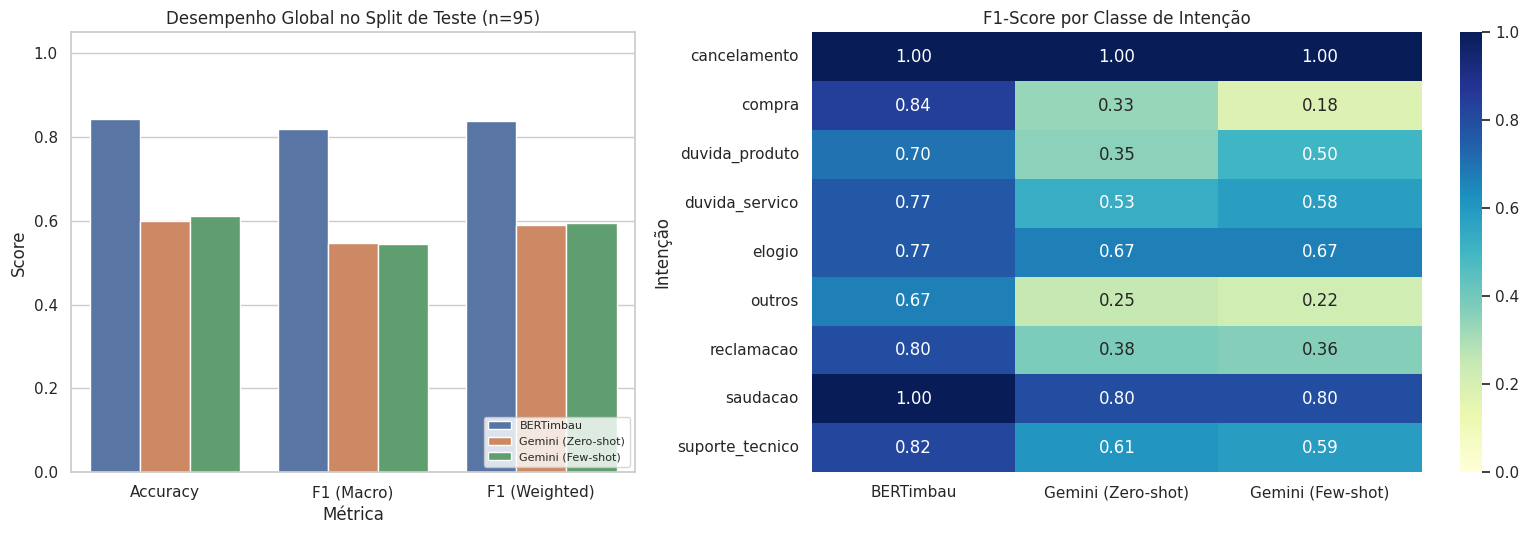

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from src.metrics_and_cost import build_comparison_table

sns.set_theme(style="whitegrid")

zs_label = f"Gemini (Zero-shot)"
fs_label = f"Gemini (Few-shot)"
bert_label = "BERTimbau"

model_results = {
    bert_label: {"metrics": bert_metrics, "stats": bert_stats},
    zs_label: {"metrics": zs_metrics, "stats": zs_stats},
    fs_label: {"metrics": fs_metrics, "stats": fs_stats},
}

df_comparison = build_comparison_table(model_results)
display(df_comparison)

# Gráficos: Métricas Globais + F1 por Classe
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.35]})

global_melted = df_comparison.melt(
    id_vars="Model",
    value_vars=["Accuracy", "F1 (Macro)", "F1 (Weighted)"],
    var_name="Métrica",
    value_name="Score",
)
sns.barplot(data=global_melted, x="Métrica", y="Score", hue="Model", ax=axes[0])
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Desempenho Global no Split de Teste (n=95)")
axes[0].legend(loc="lower right", fontsize=8)

per_class_f1 = pd.DataFrame(
    {
        bert_label: [bert_metrics["report_dict"][c]["f1-score"] for c in INTENT_LABELS],
        zs_label: [zs_metrics["report_dict"][c]["f1-score"] for c in INTENT_LABELS],
        fs_label: [fs_metrics["report_dict"][c]["f1-score"] for c in INTENT_LABELS],
    },
    index=list(INTENT_LABELS),
)
sns.heatmap(per_class_f1, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("F1-Score por Classe de Intenção")
axes[1].set_ylabel("Intenção")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

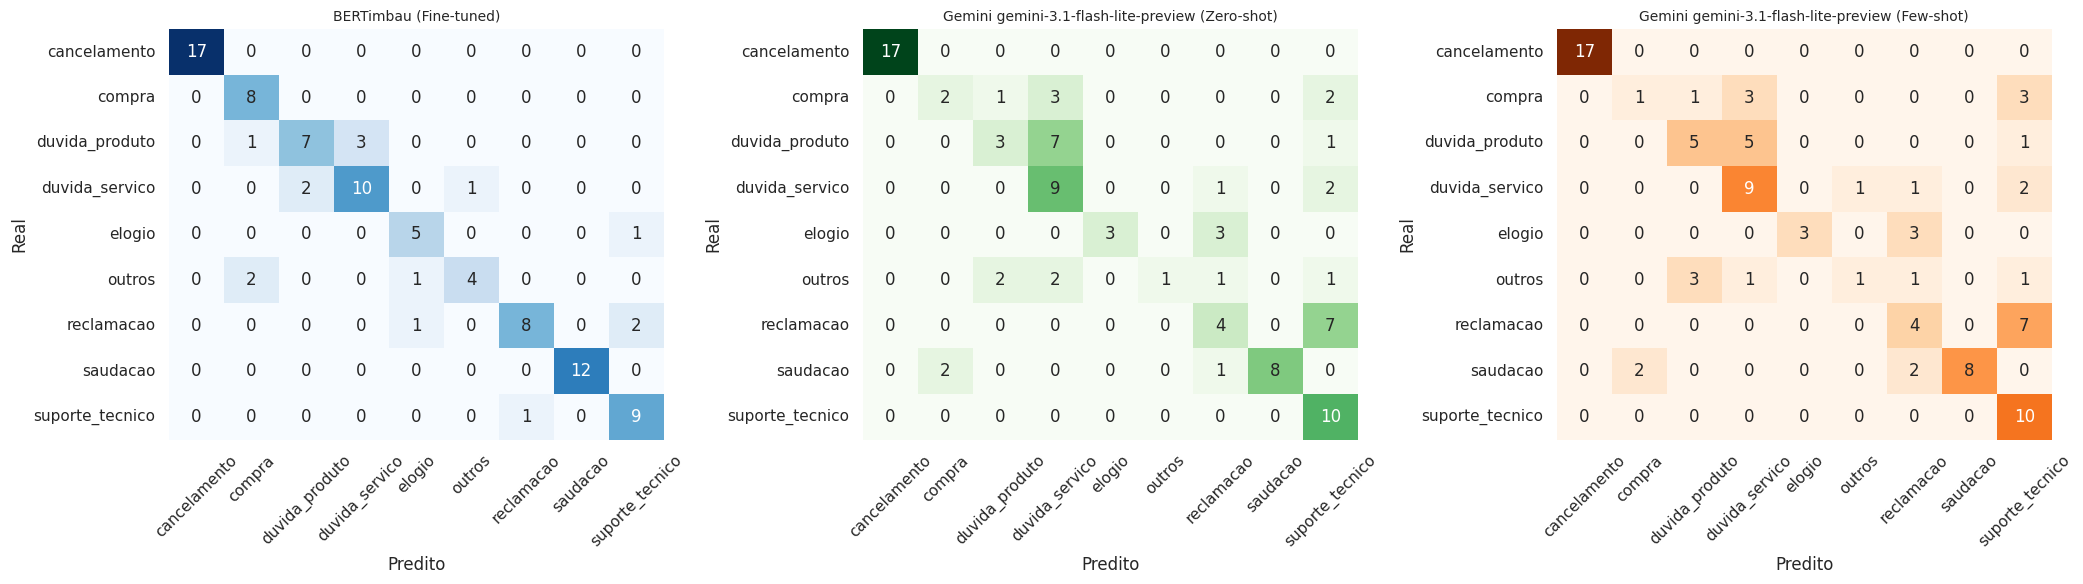

Total de amostras com ao menos um erro/discordância: 41 de 95


,idx,mensagem,real,bertimbau,gemini_zero_shot,gemini_few_shot
2,2,"Oi, vc pode me ajudar a escolher um plano de i...",compra,compra,duvida_servico,duvida_servico
3,3,"oi, vc tem algum desconto para compra de eletr...",compra,compra,duvida_produto,duvida_produto
4,4,"Oi, vc pode me ajudar? Estou tendo problema co...",suporte_tecnico,reclamacao,suporte_tecnico,suporte_tecnico
5,5,"Oi, vc pode me ajudar com um problema? Eu comp...",outros,outros,reclamacao,reclamacao
7,7,"Oi, vc pode me ajudar com um problema que eu t...",reclamacao,reclamacao,suporte_tecnico,suporte_tecnico
8,8,"Olá, eu tive um problema com o seu software on...",reclamacao,reclamacao,suporte_tecnico,suporte_tecnico
9,9,"Oi, vc pode me ajudar com um problema que eu t...",reclamacao,reclamacao,suporte_tecnico,suporte_tecnico
11,11,"Oi, vc tem algum plano de servico que possa me...",compra,compra,duvida_servico,duvida_servico
16,16,"Oi, td bem? Fiz um pedido pelo app ontem e tiv...",reclamacao,reclamacao,suporte_tecnico,suporte_tecnico
18,18,"Oi, vc pode me ajudar? Quero contratar um plan...",compra,compra,compra,suporte_tecnico


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
cms = [
    (bert_label, bert_metrics["confusion_matrix"], "Blues"),
    (zs_label, zs_metrics["confusion_matrix"], "Greens"),
    (fs_label, fs_metrics["confusion_matrix"], "Oranges"),
]

for ax, (title, cm, cmap) in zip(axes, cms):
    sns.heatmap(
        np.array(cm),
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=INTENT_LABELS,
        yticklabels=INTENT_LABELS,
        cbar=False,
        ax=ax,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Análise qualitativa de erros e discordâncias
df_errors = pd.DataFrame(
    {
        "idx": range(len(X_test)),
        "mensagem": X_test,
        "real": y_test,
        "bertimbau": df_bert["pred_label"].tolist(),
        "gemini_zero_shot": df_zs["pred_label"].tolist(),
        "gemini_few_shot": df_fs["pred_label"].tolist(),
    }
)
disagreements = df_errors[
    (df_errors["bertimbau"] != df_errors["real"])
    | (df_errors["gemini_zero_shot"] != df_errors["real"])
    | (df_errors["gemini_few_shot"] != df_errors["real"])
]
print(f"Total de amostras com ao menos um erro/discordância: {len(disagreements)} de {len(X_test)}")
display(disagreements.head(20))

## 8. Projeção de Custos e Viabilidade Econômica em Escala

=== Projeção Mensal: Gemini Zero-Shot ===


,volume_mensal,custo_por_msg_usd,api_custo_mensal_usd,Local (custo marginal) (USD),Economia vs Local (custo marginal) (%),VPS CPU básica (US$ 10/mês) (USD),Economia vs VPS CPU básica (US$ 10/mês) (%),Instância dedicada (US$ 40/mês) (USD),Economia vs Instância dedicada (US$ 40/mês) (%)
0,1000,0.000041,0.0413,0.0,100.0,10.0,-24107.40,40.0,-96729.61
1,10000,0.000041,0.4131,0.0,100.0,10.0,-2320.74,40.0,-9582.96
2,50000,0.000041,2.0655,0.0,100.0,10.0,-384.15,40.0,-1836.59
3,100000,0.000041,4.1310,0.0,100.0,10.0,-142.07,40.0,-868.30
4,500000,0.000041,20.6548,0.0,100.0,10.0,51.59,40.0,-93.66
5,1000000,0.000041,41.3097,0.0,100.0,10.0,75.79,40.0,3.17


Break-even (mensagens/mês) Zero-shot: {'Local (custo marginal)': 0.0, 'VPS CPU básica (US$ 10/mês)': 242074.027799469, 'Instância dedicada (US$ 40/mês)': 968296.111197876}

=== Projeção Mensal: Gemini Few-Shot ===


,volume_mensal,custo_por_msg_usd,api_custo_mensal_usd,Local (custo marginal) (USD),Economia vs Local (custo marginal) (%),VPS CPU básica (US$ 10/mês) (USD),Economia vs VPS CPU básica (US$ 10/mês) (%),Instância dedicada (US$ 40/mês) (USD),Economia vs Instância dedicada (US$ 40/mês) (%)
0,1000,0.000077,0.0774,0.0,100.0,10.0,-12826.23,40.0,-51604.90
1,10000,0.000077,0.7736,0.0,100.0,10.0,-1192.62,40.0,-5070.49
2,50000,0.000077,3.8681,0.0,100.0,10.0,-158.52,40.0,-934.10
3,100000,0.000077,7.7362,0.0,100.0,10.0,-29.26,40.0,-417.05
4,500000,0.000077,38.6811,0.0,100.0,10.0,74.15,40.0,-3.41
5,1000000,0.000077,77.3621,0.0,100.0,10.0,87.07,40.0,48.30


Break-even (mensagens/mês) Few-shot: {'Local (custo marginal)': 0.0, 'VPS CPU básica (US$ 10/mês)': 129262.25270090075, 'Instância dedicada (US$ 40/mês)': 517049.010803603}


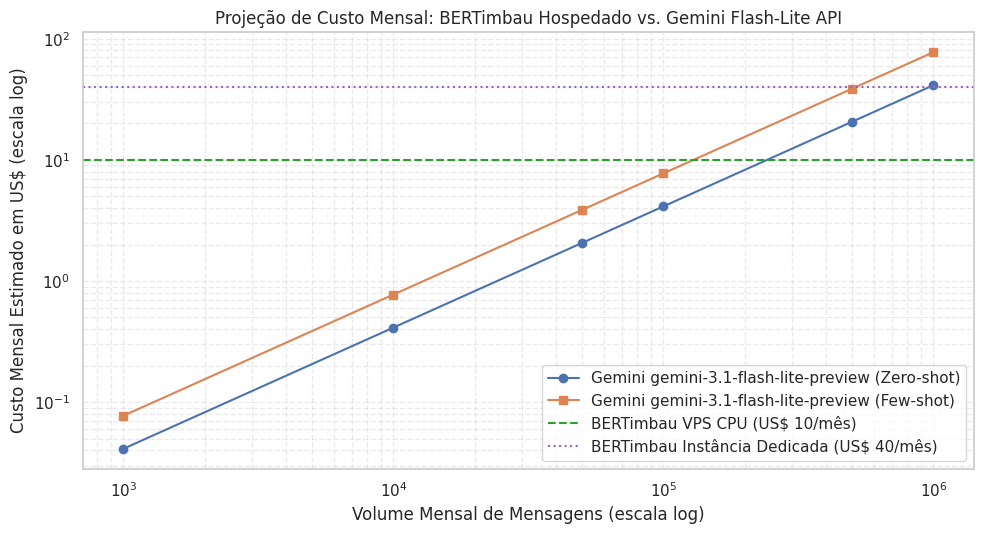

In [14]:
from src.metrics_and_cost import project_monthly_costs

VOLUMES = (1_000, 10_000, 50_000, 100_000, 500_000, 1_000_000)

df_cost_zs, breakeven_zs = project_monthly_costs(
    avg_prompt_tokens=zs_stats["avg_prompt_tokens"],
    avg_output_tokens=zs_stats["avg_output_tokens"],
    input_price_per_1m=INPUT_PRICE_PER_1M,
    output_price_per_1m=OUTPUT_PRICE_PER_1M,
    volumes=VOLUMES,
)
df_cost_fs, breakeven_fs = project_monthly_costs(
    avg_prompt_tokens=fs_stats["avg_prompt_tokens"],
    avg_output_tokens=fs_stats["avg_output_tokens"],
    input_price_per_1m=INPUT_PRICE_PER_1M,
    output_price_per_1m=OUTPUT_PRICE_PER_1M,
    volumes=VOLUMES,
)

print("=== Projeção Mensal: Gemini Zero-Shot ===")
display(df_cost_zs)
print("Break-even (mensagens/mês) Zero-shot:", breakeven_zs)

print("\n=== Projeção Mensal: Gemini Few-Shot ===")
display(df_cost_fs)
print("Break-even (mensagens/mês) Few-shot:", breakeven_fs)

# Gráfico de escala de custos (escala logarítmica)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(df_cost_zs["volume_mensal"], df_cost_zs["api_custo_mensal_usd"], marker="o", label=zs_label)
ax.plot(df_cost_fs["volume_mensal"], df_cost_fs["api_custo_mensal_usd"], marker="s", label=fs_label)
ax.axhline(10.0, linestyle="--", color="tab:green", label="BERTimbau VPS CPU (US$ 10/mês)")
ax.axhline(40.0, linestyle=":", color="tab:purple", label="BERTimbau Instância Dedicada (US$ 40/mês)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Volume Mensal de Mensagens (escala log)")
ax.set_ylabel("Custo Mensal Estimado em US$ (escala log)")
ax.set_title("Projeção de Custo Mensal: BERTimbau Hospedado vs. Gemini Flash-Lite API")
ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "cost_projection.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Exportação dos Artefatos Finais

In [15]:
import json

df_comparison.to_csv(OUTPUT_DIR / "comparison_table.csv", index=False)
df_bert.to_csv(OUTPUT_DIR / "predictions_bertimbau.csv", index=False)
df_zs.to_csv(OUTPUT_DIR / "predictions_gemini_zero_shot.csv", index=False)
df_fs.to_csv(OUTPUT_DIR / "predictions_gemini_few_shot.csv", index=False)
df_cost_zs.to_csv(OUTPUT_DIR / "cost_projection_zero_shot.csv", index=False)
df_cost_fs.to_csv(OUTPUT_DIR / "cost_projection_few_shot.csv", index=False)
disagreements.to_csv(OUTPUT_DIR / "error_analysis.csv", index=False)

summary_payload = {
    "gemini_model": GEMINI_MODEL,
    "mock_mode": USE_MOCK_LLM,
    "test_size": len(X_test),
    "k_per_class_few_shot": K_PER_CLASS,
    "pricing_usd_per_1m_tokens": {
        "input": INPUT_PRICE_PER_1M,
        "output": OUTPUT_PRICE_PER_1M,
    },
    "comparison_table": df_comparison.to_dict(orient="records"),
    "breakeven_messages_per_month": {
        "zero_shot": breakeven_zs,
        "few_shot": breakeven_fs,
    },
}

summary_path = OUTPUT_DIR / "comparison_summary.json"
summary_path.write_text(json.dumps(summary_payload, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Artefatos salvos em: {OUTPUT_DIR}")

Artefatos salvos em: /content/drive/MyDrive/Modelos_Triagem/results
